In [26]:
import tensorflow as tf
import numpy as np
import pandas as pd
from numpy import loadtxt
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input, Dropout, BatchNormalization, Activation
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler
from numpy import exp
from tensorflow.keras import Model

from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import accuracy_score,mean_absolute_error,mean_squared_error
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from keras.wrappers.scikit_learn import KerasRegressor,KerasClassifier

import torch
from torch import nn
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

pd.set_option('max_rows',999)

### Define Function

In [2]:
def create_model_neurons():
    # create model
    model = Sequential()
    model.add(Dense(64, input_dim=22, kernel_initializer='uniform'))
    model.add(Activation('relu'))
    model.add(Dropout(.15))
    
    model.add(Dense(64))
    model.add(Activation('relu'))
    model.add(Dropout(.15))
    
    model.add(Dense(64))
    model.add(Activation('relu'))
    model.add(Dropout(.15))
    model.add(Dense(1))
    # Compile model
    model.compile(loss='mean_squared_error',optimizer='Adam', metrics=['mse'])
    return model


### Import data

In [3]:
df_sunspots = pd.read_csv('data/data.csv.txt')

In [4]:
# Split month
df_sunspots.columns = ['Data','Sunspots']
df_sunspots['Month'] = df_sunspots.Data.apply(lambda x: int(x.split('-')[1]))

#build phase space
m = 10
df_phase=pd.DataFrame([df_sunspots.Sunspots.iloc[-m+d:d].values for d in range(df_sunspots.shape[0])])
df_phase.columns =['Sunspots_'+str(col-10) for col in df_phase.columns]
df_target = df_sunspots['Sunspots'].iloc[m:]

#get month dummies 
df_data=pd.concat([pd.get_dummies(df_sunspots.Month,prefix='Month_'),df_phase],axis=1).iloc[m:]
df_data.set_index(df_sunspots['Data'].iloc[m:],inplace=True)

C:\Users\diego\anaconda3\lib\site-packages\seaborn\_decorators.py:36: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='Data', ylabel='Sunspots'>

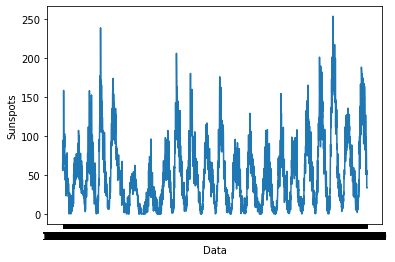

In [26]:
sns.lineplot(df_sunspots['Data'],df_sunspots['Sunspots'])

### Train split

In [5]:
X=df_data.values
y=df_target.values

In [6]:
tscv = TimeSeriesSplit(n_splits=2,test_size=30)

In [7]:
for train_index, test_index in tscv.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

In [8]:
tscv = TimeSeriesSplit(n_splits=2,test_size=30)

In [9]:
for train_index, test_index in tscv.split(X_train):
    X_train_2, X_valid = X_train[train_index], X_train[test_index]
    y_train_2, y_valid = y_train[train_index], y_train[test_index]

## Define Model and Parameters

In [31]:
# define model tensorflow

model = Sequential()
model.add(Dense(8, input_dim=22, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1))

opt = keras.optimizers.Adam(learning_rate=0.01)
model.compile(loss='mean_squared_error', optimizer=opt)


## Train Model

In [33]:
%%time
model.fit(X_train_2, y_train_2, epochs=400, batch_size=10,validation_data=(X_valid,y_valid),validation_batch_size=20)

Epoch 1/400
275/275 [==============================] - 0s 2ms/step - loss: 246.8387 - val_loss: 651.7155
Epoch 2/400
275/275 [==============================] - 0s 2ms/step - loss: 247.6049 - val_loss: 737.8829
Epoch 3/400
275/275 [==============================] - 0s 2ms/step - loss: 251.2803 - val_loss: 563.2569
Epoch 4/400
275/275 [==============================] - 0s 2ms/step - loss: 247.3063 - val_loss: 654.9737
Epoch 5/400
275/275 [==============================] - 0s 1ms/step - loss: 254.3926 - val_loss: 883.0145
Epoch 6/400
275/275 [==============================] - 0s 1ms/step - loss: 243.5343 - val_loss: 572.1937
Epoch 7/400
275/275 [==============================] - 0s 1ms/step - loss: 248.0878 - val_loss: 629.1819
Epoch 8/400
275/275 [==============================] - 0s 1ms/step - loss: 245.2447 - val_loss: 569.0706
Epoch 9/400
275/275 [==============================] - 0s 1ms/step - loss: 242.0727 - val_loss: 866.4998
Epoch 10/400
275/275 [==============================] -

275/275 [==============================] - 0s 1ms/step - loss: 243.9844 - val_loss: 562.5426
Epoch 79/400
275/275 [==============================] - 0s 1ms/step - loss: 246.6249 - val_loss: 630.8799
Epoch 80/400
275/275 [==============================] - 0s 1ms/step - loss: 248.6682 - val_loss: 1119.3842
Epoch 81/400
275/275 [==============================] - 0s 1ms/step - loss: 253.7679 - val_loss: 919.9005
Epoch 82/400
275/275 [==============================] - 0s 1ms/step - loss: 242.6284 - val_loss: 571.3467
Epoch 83/400
275/275 [==============================] - 0s 2ms/step - loss: 247.0810 - val_loss: 559.7269
Epoch 84/400
275/275 [==============================] - 0s 1ms/step - loss: 248.3487 - val_loss: 600.4274
Epoch 85/400
275/275 [==============================] - 0s 2ms/step - loss: 244.9551 - val_loss: 679.9308
Epoch 86/400
275/275 [==============================] - 0s 1ms/step - loss: 240.8065 - val_loss: 598.7584
Epoch 87/400
275/275 [==============================] - 0s

Epoch 155/400
275/275 [==============================] - 0s 1ms/step - loss: 250.0932 - val_loss: 560.3186
Epoch 156/400
275/275 [==============================] - 0s 1ms/step - loss: 248.8673 - val_loss: 562.0391
Epoch 157/400
275/275 [==============================] - 0s 2ms/step - loss: 242.1163 - val_loss: 694.4719
Epoch 158/400
275/275 [==============================] - 0s 1ms/step - loss: 257.2750 - val_loss: 559.6974
Epoch 159/400
275/275 [==============================] - 0s 2ms/step - loss: 248.7106 - val_loss: 561.1367
Epoch 160/400
275/275 [==============================] - 0s 1ms/step - loss: 249.1886 - val_loss: 559.7880
Epoch 161/400
275/275 [==============================] - 0s 1ms/step - loss: 246.5548 - val_loss: 558.8223
Epoch 162/400
275/275 [==============================] - 0s 1ms/step - loss: 255.2278 - val_loss: 831.0086
Epoch 163/400
275/275 [==============================] - 0s 1ms/step - loss: 240.4593 - val_loss: 688.1610
Epoch 164/400
275/275 [==============

275/275 [==============================] - 0s 1ms/step - loss: 250.2462 - val_loss: 574.8011
Epoch 232/400
275/275 [==============================] - 0s 1ms/step - loss: 247.8271 - val_loss: 650.8749
Epoch 233/400
275/275 [==============================] - 0s 1ms/step - loss: 249.5954 - val_loss: 560.5348
Epoch 234/400
275/275 [==============================] - 0s 1ms/step - loss: 243.4344 - val_loss: 870.7809
Epoch 235/400
275/275 [==============================] - 0s 1ms/step - loss: 247.8231 - val_loss: 605.6101
Epoch 236/400
275/275 [==============================] - 1s 2ms/step - loss: 240.6480 - val_loss: 610.2146
Epoch 237/400
275/275 [==============================] - 0s 1ms/step - loss: 253.0521 - val_loss: 602.9852
Epoch 238/400
275/275 [==============================] - 0s 1ms/step - loss: 246.1859 - val_loss: 577.6445
Epoch 239/400
275/275 [==============================] - 0s 2ms/step - loss: 244.8865 - val_loss: 579.7161
Epoch 240/400
275/275 [============================

275/275 [==============================] - 1s 3ms/step - loss: 255.7517 - val_loss: 591.0883
Epoch 308/400
275/275 [==============================] - 1s 2ms/step - loss: 238.6037 - val_loss: 679.6326
Epoch 309/400
275/275 [==============================] - 1s 3ms/step - loss: 246.5443 - val_loss: 564.9260
Epoch 310/400
275/275 [==============================] - 1s 3ms/step - loss: 253.0466 - val_loss: 660.9932
Epoch 311/400
275/275 [==============================] - 1s 2ms/step - loss: 247.6122 - val_loss: 562.0349
Epoch 312/400
275/275 [==============================] - 1s 3ms/step - loss: 247.6670 - val_loss: 564.0529
Epoch 313/400
275/275 [==============================] - 1s 2ms/step - loss: 253.0312 - val_loss: 962.3373
Epoch 314/400
275/275 [==============================] - 0s 2ms/step - loss: 242.4641 - val_loss: 777.3664
Epoch 315/400
275/275 [==============================] - 0s 1ms/step - loss: 246.6365 - val_loss: 789.9630
Epoch 316/400
275/275 [============================

275/275 [==============================] - 0s 1ms/step - loss: 249.7388 - val_loss: 625.9578
Epoch 384/400
275/275 [==============================] - 0s 2ms/step - loss: 239.8914 - val_loss: 566.6273
Epoch 385/400
275/275 [==============================] - 0s 1ms/step - loss: 244.9562 - val_loss: 590.4219
Epoch 386/400
275/275 [==============================] - 0s 2ms/step - loss: 247.5533 - val_loss: 562.6574
Epoch 387/400
275/275 [==============================] - 0s 1ms/step - loss: 246.5038 - val_loss: 831.8969
Epoch 388/400
275/275 [==============================] - 1s 2ms/step - loss: 244.5110 - val_loss: 569.9767
Epoch 389/400
275/275 [==============================] - 0s 2ms/step - loss: 247.2508 - val_loss: 578.0029
Epoch 390/400
275/275 [==============================] - 0s 2ms/step - loss: 245.1339 - val_loss: 590.4104
Epoch 391/400
275/275 [==============================] - 0s 2ms/step - loss: 243.4626 - val_loss: 567.4304
Epoch 392/400
275/275 [============================

In [35]:
preds = model.predict(X_test)
print('MAE: %.2f' % mean_absolute_error(y_test,preds))

MAE: 17.57
